# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "MAZKO"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [ ]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [ ]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [ ]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

count    33480.000
mean       315.755
std        377.596
min          0.700
25%         94.500
50%        220.600
75%        356.200
max       3111.300
Name: y, dtype: float64
нулі: 0.0 | пропуски: 0
кроки часу != 1h: 0


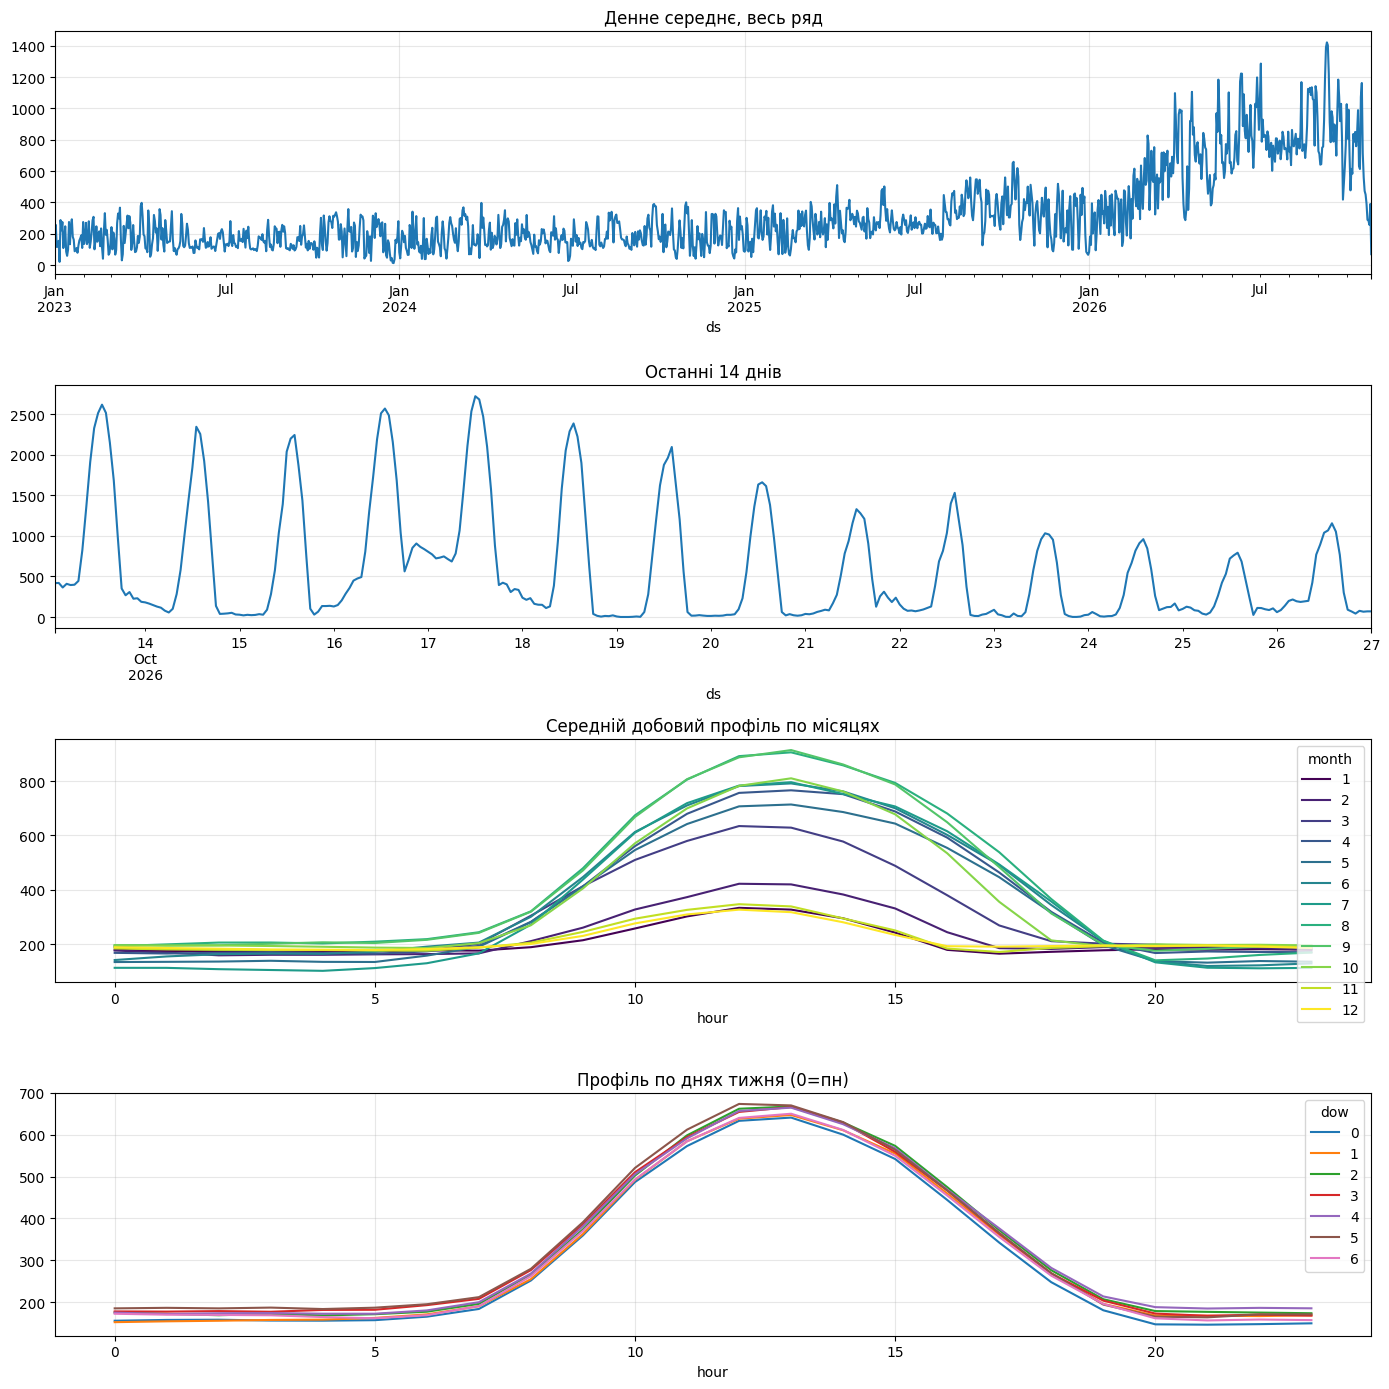

y              1.00
cloud_cover    0.16
temperature    0.28
wind_speed     0.30
pressure      -0.02
humidity      -0.38
daylight       0.39
air_density   -0.26
Name: y, dtype: float64

Жовтень-листопад:
 y              1.00
cloud_cover    0.15
temperature    0.35
wind_speed     0.28
pressure      -0.00
humidity      -0.35
daylight       0.41
air_density   -0.30
Name: y, dtype: float64


AttributeError: 'float' object has no attribute 'round'

In [ ]:
# Your work here.
import matplotlib.pyplot as plt

df = data.set_index("ds").copy()
df["hour"] = df.index.hour
df["month"] = df.index.month
df["dow"] = df.index.dayofweek

print(df["y"].describe())
print("нулі:", (df["y"] == 0).mean().round(3), "| пропуски:", df["y"].isna().sum())
print("кроки часу != 1h:", (df.index.to_series().diff().dropna() != pd.Timedelta(hours=1)).sum())

fig, ax = plt.subplots(4, 1, figsize=(14, 14))

# 1) весь ряд (денні середні)
df["y"].resample("D").mean().plot(ax=ax[0], title="Денне середнє, весь ряд")

# 2) останні 14 днів погодинно
df["y"].iloc[-24*14:].plot(ax=ax[1], title="Останні 14 днів")

# 3) добовий профіль по місяцях
df.pivot_table(index="hour", columns="month", values="y", aggfunc="mean").plot(
    ax=ax[2], title="Середній добовий профіль по місяцях", colormap="viridis")

# 4) профіль по днях тижня
df.pivot_table(index="hour", columns="dow", values="y", aggfunc="mean").plot(
    ax=ax[3], title="Профіль по днях тижня (0=пн)")

plt.tight_layout(); plt.show()

# кореляція з погодою
wcols = ["cloud_cover","temperature","wind_speed","pressure","humidity","daylight","air_density"]
print(df[["y"] + wcols].corr()["y"].round(2))

# те саме тільки для жовтня-листопада (наш сезон)
sub = df[df["month"].isin([10, 11])]
print("\nЖовтень-листопад:\n", sub[["y"] + wcols].corr()["y"].round(2))

# як схожі на горизонт погодинні значення за останні роки (27-29 жовтня)
for yr in [2023, 2024, 2025]:
    s = df.loc[f"{yr}-10-27":f"{yr}-10-29", "y"]
    print(yr, "середнє:", s.mean().round(1), "макс:", s.max().round(1))

# прогноз погоди на горизонт
print(weather_fc.describe().round(2))

### Lightgbm

In [ ]:
import lightgbm as lgb   # якщо немає: !pip install lightgbm

d = data.set_index("ds")
yarr = d["y"].to_numpy(float)
W = ["cloud_cover","temperature","wind_speed","pressure","humidity","daylight","air_density"]
Warr = d[W].to_numpy(float)
idx = d.index
n = len(d)

h = np.arange(1, 49); k = (h - 1) // 24; off = h - 24 * (k + 1)   # зсув до тієї ж години вчора

def rows(i, wx, hours):
    """i = позиція останньої відомої години (опівночі); wx = погода на 48 годин; hours = їхні мітки часу"""
    hist = yarr[:i + 1]
    lv7, lv1, pk1 = hist[-168:].mean(), hist[-24:].mean(), hist[-24:].max()
    X = np.column_stack([
        hours.hour, hours.dayofyear, k, h, wx,
        hist[-1 + off] / lv7, hist[-1 + off - 24] / lv7,
        np.full(48, lv1 / lv7), np.full(48, pk1 / lv7)])
    return X, lv7

# навчальна вибірка: кожна північ як точка "відліку", ціль - наступні 48 годин
origins = [i for i in range(200, n - 48) if idx[i].hour == 0]
Xs, Ys, Ls, Os = [], [], [], []
for i in origins:
    X, lv = rows(i, Warr[i + 1:i + 49], idx[i + 1:i + 49])
    Xs.append(X); Ys.append(yarr[i + 1:i + 49] / lv); Ls.append(np.full(48, lv)); Os.append(np.full(48, i))
X_all, Y_all, L_all, O_all = map(np.concatenate, (Xs, Ys, Ls, Os))
DAYLIGHT_COL = 4 + W.index("daylight")

def fit(mask):
    m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, verbose=-1)
    m.fit(X_all[mask], Y_all[mask], sample_weight=L_all[mask])
    return m

# --- валідація: 3 послідовні блоки по 30 відліків (останні 90 днів), навчання лише на минулому ---
blocks = np.array_split(np.array(origins[-90:]), 3)
oof = []   # (блок, origin, y, pred, lv, k, daylight)
for b, bl in enumerate(blocks):
    m = fit(O_all < bl[0] - 48)
    te = np.isin(O_all, bl)
    p = np.clip(m.predict(X_all[te]), 0, None)
    oof.append(dict(b=np.full(te.sum(), b), o=O_all[te], y=Y_all[te] * L_all[te], p=p * L_all[te],
                    r=Y_all[te] - p, lv=L_all[te], k=X_all[te][:, 2], dl=X_all[te][:, DAYLIGHT_COL]))
oof = pd.DataFrame({c: np.concatenate([o[c] for o in oof]) for c in oof[0]})

def calib(df):
    """квантилі нормованих залишків по (доба, день/ніч)"""
    return {g: (df.loc[m.index, "r"].quantile(0.025), df.loc[m.index, "r"].quantile(0.975))
            for g, m in df.groupby(["k", "dl"])}

def interval(df, q):
    lo = np.array([q[(a, b)][0] for a, b in zip(df.k, df.dl)])
    hi = np.array([q[(a, b)][1] for a, b in zip(df.k, df.dl)])
    pred = df.p.to_numpy()
    return pred, np.clip(pred + lo * df.lv, 0, None), pred + hi * df.lv

# калібруємо на блоках 0-1, чесно тестуємо на блоці 2 і порівнюємо зі snaive на тих самих відліках
q = calib(oof[oof.b < 2])
test = oof[oof.b == 2]
pred, lo, hi = interval(test, q)
res_model = score(test.y, pred, lo, hi)

sn_pred, sn_lo, sn_hi = [], [], []
for i in sorted(test.o.unique()):
    p_, l_, u_ = snaive(yarr[:int(i) + 1]); sn_pred.append(p_); sn_lo.append(l_); sn_hi.append(u_)
res_sn = score(test.sort_values(["o", "k"]).y if False else np.concatenate([yarr[int(i)+1:int(i)+49] for i in sorted(test.o.unique())]),
               np.concatenate(sn_pred), np.concatenate(sn_lo), np.concatenate(sn_hi))

# model-ряди в тому ж порядку (за o, потім година) для чесного порівняння
results.loc["LightGBM (block 3, 30 origins)"] = res_model
results.loc["seasonal naive (block 3, 30 origins)"] = res_sn
print("skill (RMSE model / RMSE snaive):", round(res_model["RMSE"] / res_sn["RMSE"], 3))
results

skill (RMSE model / RMSE snaive): 0.885


,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
"LightGBM (block 3, 30 origins)",324.199,592.441,1983.699,0.794
"seasonal naive (block 3, 30 origins)",366.348,540.980,3029.563,0.742


In [ ]:
# фінальна модель на всій історії
m_final = fit(np.ones(len(O_all), bool))

# квантилі з усіх out-of-fold залишків
q_all = calib(oof)
WIDEN = 1.0   # якщо coverage у валідації < 0.93, постав 1.15

i0 = n - 1                                   # остання відома година: 2026-10-27 00:00
fut = pd.DatetimeIndex(FUTURE)
X_f, lv_f = rows(i0, weather_fc[W].to_numpy(float), fut)
p_f = np.clip(m_final.predict(X_f), 0, None) * lv_f

dl = X_f[:, DAYLIGHT_COL]
lo_f = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f * WIDEN
hi_f = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f * WIDEN

sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"),
                    "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_f, 0, None),
                    "upper_95": p_f + hi_f})
sub.to_csv("MAZKO_project.csv", index=False)     # заміни SURNAME на своє прізвище
print(sub.head(30).round(1))
# далі запусти check_submission з шаблону на цьому файлі

                     ds  forecast  lower_95  upper_95
0   2026-10-27 01:00:00     248.8      47.2     369.1
1   2026-10-27 02:00:00     230.4      28.8     350.7
2   2026-10-27 03:00:00     233.1      31.4     353.3
3   2026-10-27 04:00:00     176.8       0.0     297.0
4   2026-10-27 05:00:00     206.3       4.7     326.5
5   2026-10-27 06:00:00     210.7       9.1     331.0
6   2026-10-27 07:00:00     165.9       0.0     448.7
7   2026-10-27 08:00:00     191.5       0.0     474.3
8   2026-10-27 09:00:00     316.3     113.5     599.1
9   2026-10-27 10:00:00     483.9     281.1     766.7
10  2026-10-27 11:00:00     566.2     363.4     849.0
11  2026-10-27 12:00:00     750.7     547.9    1033.5
12  2026-10-27 13:00:00     748.3     545.5    1031.1
13  2026-10-27 14:00:00     766.6     563.8    1049.4
14  2026-10-27 15:00:00     637.6     434.8     920.4
15  2026-10-27 16:00:00     371.9     170.3     492.2
16  2026-10-27 17:00:00     199.6       0.0     319.8
17  2026-10-27 18:00:00     

### Another tryies

In [ ]:
import warnings; warnings.filterwarnings("ignore")
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

O90 = [int(i) for i in origins[-90:]]
B90 = np.repeat([0, 1, 2], 30)
WI = {c: W.index(c) for c in W}

def mean3_fc(i, wx=None):
    # середнє тієї ж години за останні 3 доби (відносно проста, але з свіжим рівнем)
    return np.array([np.mean([yarr[i + 1 - 24 + (j % 24) - 24 * t] for t in range(3)]) for j in range(48)])

def ets_fc(i, wx=None):
    s = np.log1p(yarr[i - 24 * 28 + 1:i + 1])
    m = ExponentialSmoothing(s, trend="add", damped_trend=True,
                             seasonal="add", seasonal_periods=24).fit()
    return np.expm1(m.forecast(48))

def sarimax_fc(i, wx=None):
    cols = [WI["daylight"], WI["cloud_cover"], WI["wind_speed"]]
    Xh = Warr[i - 24 * 14 + 1:i + 1][:, cols]
    Xf = (Warr[i + 1:i + 49] if wx is None else wx)[:, cols]
    try:
        m = SARIMAX(np.log1p(yarr[i - 24 * 14 + 1:i + 1]), exog=Xh,
                    order=(1, 0, 0), seasonal_order=(1, 0, 0, 24),
                    enforce_stationarity=False, enforce_invertibility=False,
                    initialization="approximate_diffuse").fit(disp=False, maxiter=100)
        out = np.expm1(m.forecast(48, exog=Xf))
        if not np.all(np.isfinite(out)) or out.max() > 5 * yarr[i - 24 * 14 + 1:i + 1].max():
            raise ValueError("diverged")
        return out
    except Exception:
        return ets_fc(i)

def make_df(P):
    rows = []
    for b, o in zip(B90, O90):
        y_ = yarr[o + 1:o + 49]; lv = yarr[:o + 1][-168:].mean(); p = np.clip(P[o], 0, None)
        rows.append(pd.DataFrame(dict(b=b, o=o, y=y_, p=p, lv=lv, r=(y_ - p) / lv,
                                      k=(np.arange(48)) // 24, dl=Warr[o + 1:o + 49, WI["daylight"]])))
    return pd.concat(rows, ignore_index=True)

def evaluate(P):
    df = make_df(P)
    q = calib(df[df.b < 2])
    te = df[df.b == 2]
    pred, lo, hi = interval(te, q)
    return score(te.y, pred, lo, hi)

P = {}
P["lgbm"] = {o: oof[oof.o == o].p.to_numpy() for o in O90}      # з комірки 1
P["mean3"] = {o: mean3_fc(o) for o in O90}
P["ets"] = {o: ets_fc(o) for o in O90}
P["sarimax"] = {o: sarimax_fc(o) for o in O90}                  # може йти 1-3 хв

def ens(names): return {o: np.mean([P[n][o] for n in names], axis=0) for o in O90}
P["lgbm+ets"] = ens(["lgbm", "ets"])
P["lgbm+sarimax"] = ens(["lgbm", "sarimax"])
P["lgbm+ets+sarimax"] = ens(["lgbm", "ets", "sarimax"])
P["all4"] = ens(["lgbm", "ets", "sarimax", "mean3"])

tab = pd.DataFrame({n: evaluate(p) for n, p in P.items()}).T
tab.loc["snaive (ті самі відліки)"] = results.loc["seasonal naive (block 3, 30 origins)"]
tab["skill"] = tab["RMSE"] / tab.loc["snaive (ті самі відліки)", "RMSE"]
print(tab.round(3).sort_values("Winkler"))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                             RMSE     MAPE   Winkler  coverage  skill
lgbm+sarimax              457.681  419.310  1798.559     0.907  1.249
all4                      393.401  385.066  1922.041     0.892  1.074
lgbm                      324.199  592.441  1983.699     0.794  0.885
lgbm+ets                  420.231  421.657  2066.790     0.874  1.147
lgbm+ets+sarimax          483.441  365.144  2133.661     0.890  1.320
mean3                     368.160  465.185  2304.436     0.776  1.005
sarimax                   776.848  279.430  2427.500     0.908  2.121
ets                       755.793  276.175  2546.375     0.890  2.063
snaive (ті самі відліки)  366.348  540.980  3029.563     0.742  1.000


In [ ]:
def pt(Pn):
    ys = np.concatenate([yarr[o+1:o+49] for o in O90])
    ps = np.concatenate([np.clip(Pn[o], 0, None) for o in O90])
    return rmse(ys, ps), mape(ys, ps)

P["snaive"] = {o: snaive(yarr[:o+1])[0] for o in O90}
for w in [0.5, 0.7, 0.85]:
    P[f"lgbm{w}+mean3"] = {o: w*P["lgbm"][o] + (1-w)*P["mean3"][o] for o in O90}

def evaluate_w(Pn, wide=1.0):
    df = make_df(Pn); q = calib(df[df.b < 2]); te = df[df.b == 2]
    pred, lo, hi = interval(te, q)
    lo = np.clip(pred - (pred - lo) * wide, 0, None); hi = pred + (hi - pred) * wide
    return score(te.y, pred, lo, hi)

rows_ = []
for n_ in ["snaive", "lgbm", "mean3", "lgbm0.5+mean3", "lgbm0.7+mean3", "lgbm0.85+mean3"]:
    r, m = pt(P[n_])
    for wd in [1.0, 1.2, 1.4]:
        s = evaluate_w(P[n_], wd)
        rows_.append(dict(model=n_, widen=wd, RMSE90=r, MAPE90=m, **s))
print(pd.DataFrame(rows_).round(2).to_string())

             model  widen  RMSE90  MAPE90    RMSE    MAPE  Winkler  coverage
0           snaive    1.0  302.57  227.95  366.35  540.98  2427.36      0.81
1           snaive    1.2  302.57  227.95  366.35  540.98  1987.26      0.86
2           snaive    1.4  302.57  227.95  366.35  540.98  1706.60      0.91
3             lgbm    1.0  270.45  256.76  324.20  592.44  1983.70      0.79
4             lgbm    1.2  270.45  256.76  324.20  592.44  1629.98      0.88
5             lgbm    1.4  270.45  256.76  324.20  592.44  1449.14      0.93
6            mean3    1.0  303.31  201.35  368.16  465.19  2304.44      0.78
7            mean3    1.2  303.31  201.35  368.16  465.19  1825.74      0.87
8            mean3    1.4  303.31  201.35  368.16  465.19  1587.89      0.92
9    lgbm0.5+mean3    1.0  264.86  225.38  320.04  524.21  1910.02      0.79
10   lgbm0.5+mean3    1.2  264.86  225.38  320.04  524.21  1536.22      0.89
11   lgbm0.5+mean3    1.4  264.86  225.38  320.04  524.21  1377.83      0.94

In [ ]:
def rows2(i, wx, hours):
    hist = yarr[:i + 1]
    lv7, lv1, lv3, lv14 = (hist[-168:].mean(), hist[-24:].mean(), hist[-72:].mean(), hist[-336:].mean())
    pk1, pk3, mn1 = hist[-24:].max(), hist[-72:].max(), hist[-24:].min()
    def dcl(a, c):   # середнє по світлому часу доби
        return (a[:, c] * a[:, 5]).sum() / max(1, a[:, 5].sum())
    cc = np.r_[np.full(24, dcl(wx[:24], 0)), np.full(24, dcl(wx[24:], 0))]
    wd = np.r_[np.full(24, dcl(wx[:24], 2)), np.full(24, dcl(wx[24:], 2))]
    X = np.column_stack([
        hours.hour, hours.dayofyear, k, h, wx,
        hist[-1 + off] / lv7, hist[-1 + off - 24] / lv7, hist[-1 + off - 48] / lv7,
        np.full(48, lv1 / lv7), np.full(48, lv3 / lv7), np.full(48, lv14 / lv7),
        np.full(48, pk1 / lv7), np.full(48, pk3 / lv7), np.full(48, mn1 / lv7),
        np.full(48, hist[-1] / lv7), cc, wd])
    return X, lv7

X2_all = np.concatenate([rows2(i, Warr[i+1:i+49], idx[i+1:i+49])[0] for i in origins])
assert len(X2_all) == len(Y_all)

def fit2(mask, ref, seeds=(0, 1, 2), half_life_days=180):
    w = L_all[mask] * 0.5 ** ((ref - O_all[mask]) / (24 * half_life_days))
    ms = []
    for s in seeds:
        m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=s, verbose=-1)
        m.fit(X2_all[mask], Y_all[mask], sample_weight=w); ms.append(m)
    return ms

def pred2(ms, X): return np.clip(np.mean([m.predict(X) for m in ms], axis=0), 0, None)

P["lgbm2"] = {}
for bl in blocks:
    ms = fit2(O_all < bl[0] - 48, bl[0])
    for o in bl:
        te = O_all == o
        P["lgbm2"][int(o)] = pred2(ms, X2_all[te]) * L_all[te]

P["lgbm2+mean3"] = {o: 0.8 * P["lgbm2"][o] + 0.2 * P["mean3"][o] for o in O90}
rows_ = []
for n_ in ["snaive", "lgbm", "lgbm2", "lgbm2+mean3"]:
    r, m = pt(P[n_])
    for wd in [1.0, 1.3]:
        rows_.append(dict(model=n_, widen=wd, RMSE90=r, MAPE90=m, **evaluate_w(P[n_], wd)))
print(pd.DataFrame(rows_).round(2).to_string())

         model  widen  RMSE90  MAPE90    RMSE    MAPE  Winkler  coverage
0       snaive    1.0  302.57  227.95  366.35  540.98  2427.36      0.81
1       snaive    1.3  302.57  227.95  366.35  540.98  1827.85      0.88
2         lgbm    1.0  270.45  256.76  324.20  592.44  1983.70      0.79
3         lgbm    1.3  270.45  256.76  324.20  592.44  1521.79      0.90
4        lgbm2    1.0  239.98  121.52  292.07  237.49  2243.93      0.78
5        lgbm2    1.3  239.98  121.52  292.07  237.49  1700.78      0.86
6  lgbm2+mean3    1.0  236.88  135.55  289.90  280.88  2096.76      0.79
7  lgbm2+mean3    1.3  236.88  135.55  289.90  280.88  1594.45      0.88


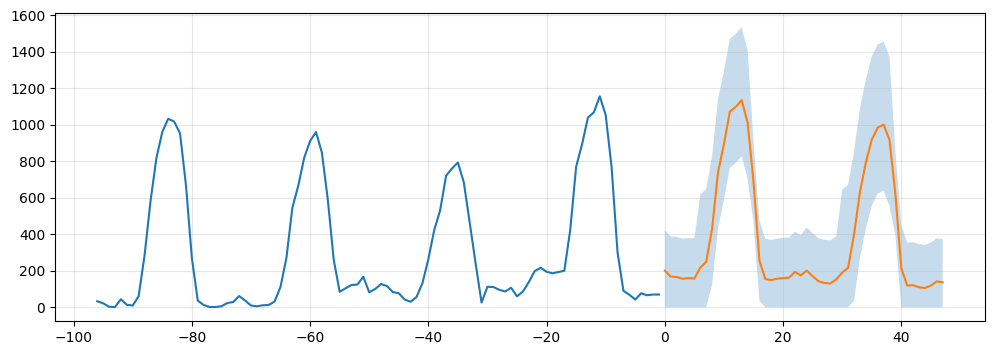

In [ ]:
NAME, WIDEN = "lgbm2+mean3", 1.5       # <- за результатами комірок 5-6
i0 = n - 1
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(i0, wx_f, fut)
ms_f = fit2(np.ones(len(O_all), bool), n)
p_f = pred2(ms_f, X_f) * lv_f
if NAME == "lgbm2+mean3":
    p_f = 0.8 * p_f + 0.2 * mean3_fc(i0)

q_all = calib(make_df(P[NAME]))
dl = wx_f[:, WI["daylight"]]
lo_r = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f
hi_r = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f
sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"), "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_r * WIDEN, 0, None),
                    "upper_95": p_f + hi_r * WIDEN})
sub.to_csv("MAZKO_lgbm2_mean3_project.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(range(-96, 0), yarr[-96:]); plt.plot(range(48), sub.forecast)
plt.fill_between(range(48), sub.lower_95, sub.upper_95, alpha=.25); plt.show()

### Шукаємо що дало найкращі зміни

In [ ]:
V1      = list(range(0, 13)) + [14, 17]       # рівно фічі v1
EXTRA_L = [13, 15, 16, 18]                    # лаг -48, рівні 3д/14д, пік 3д
NIGHT   = [19, 20]                            # нічний мінімум, остання година
DAYAGG  = [21, 22]                            # агрегована погода доби
ALL     = list(range(23))

def run(cols, half_life=180, seeds=(0,)):
    out = {}
    for bl in blocks:
        mask = O_all < bl[0] - 48
        ref = bl[0]
        w = L_all[mask] * (0.5 ** ((ref - O_all[mask]) / (24 * half_life)) if half_life else 1.0)
        Xtr = X2_all[mask][:, cols]
        ms = [lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
              min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              random_state=s, verbose=-1).fit(Xtr, Y_all[mask], sample_weight=w) for s in seeds]
        for o in bl:
            te = O_all == o
            p = np.clip(np.mean([m.predict(X2_all[te][:, cols]) for m in ms], axis=0), 0, None)
            out[int(o)] = p * L_all[te]
    return out

def report(Pn, name):
    df = make_df(Pn); d2 = df[df.k == 1]
    s = evaluate_w(Pn, 1.4)
    return dict(model=name, RMSE90=rmse(df.y, df.p), RMSE_d2=rmse(d2.y, d2.p),
                MAPE90=mape(df.y, df.p), MAPE_d2=mape(d2.y, d2.p),
                Winkler_b3=s["Winkler"], cov_b3=s["coverage"])

exps = {
  "A v1 фічі, без decay":          (V1, None),
  "B v1 + decay":                  (V1, 180),
  "C v1 + extra лаги/рівні":       (V1 + EXTRA_L, None),
  "D v1 + night(min,last)":        (V1 + NIGHT, None),
  "E v1 + day-agg погода":         (V1 + DAYAGG, None),
  "F ALL, без decay":              (ALL, None),
  "G ALL + decay":                 (ALL, 180),
  "H ALL + decay, seed=1":         (ALL, 180),          # міра шуму seed
  "-extra (G без C)":              ([c for c in ALL if c not in EXTRA_L], 180),
  "-night (G без D)":              ([c for c in ALL if c not in NIGHT], 180),
  "-dayagg (G без E)":             ([c for c in ALL if c not in DAYAGG], 180),
}
R = []
for name, (cols, hl) in exps.items():
    seeds = (1,) if "seed=1" in name else (0,)
    Pn = run(cols, hl, seeds)
    P["abl " + name] = Pn
    R.append(report(Pn, name)); print("done", name)

R.append(report(P["snaive"], "snaive"))
R.append(report(P["lgbm2+mean3"], "lgbm2+mean3 (3 seed, поточний)"))
print(pd.DataFrame(R).round(1).to_string())

done A v1 фічі, без decay
done B v1 + decay
done C v1 + extra лаги/рівні
done D v1 + night(min,last)
done E v1 + day-agg погода
done F ALL, без decay
done G ALL + decay
done H ALL + decay, seed=1
done -extra (G без C)
done -night (G без D)
done -dayagg (G без E)
                             model  RMSE90  RMSE_d2  MAPE90  MAPE_d2  Winkler_b3  cov_b3
0             A v1 фічі, без decay   271.4    290.4   274.4    277.4      1462.7     0.9
1                     B v1 + decay   265.8    283.1   245.4    271.0      1378.0     0.9
2          C v1 + extra лаги/рівні   257.1    270.9   223.2    246.3      1702.0     0.9
3           D v1 + night(min,last)   253.0    278.4   220.9    232.0      1309.4     0.9
4            E v1 + day-agg погода   267.1    284.2   189.8    176.5      1554.8     0.9
5                 F ALL, без decay   247.8    268.0   136.3    158.6      1612.9     0.9
6                    G ALL + decay   241.5    259.3   119.2    140.8      1588.0     0.9
7            H ALL + deca

In [ ]:
def with_night_scale(Pn, c):
    out = {}
    for o in O90:
        dl_ = Warr[o+1:o+49, WI["daylight"]]
        out[o] = Pn[o] * np.where(dl_ == 0, c, 1.0)
    return out

base = P["lgbm2+mean3"]
R2 = []
for c in [1.0, 0.9, 0.8, 0.7, 0.6]:
    Pn = with_night_scale(base, c)
    R2.append(report(Pn, f"night x{c}"))
print(pd.DataFrame(R2).round(1).to_string())

        model  RMSE90  RMSE_d2  MAPE90  MAPE_d2  Winkler_b3  cov_b3
0  night x1.0   236.9    255.5   135.5    153.8      1496.1     0.9
1  night x0.9   234.2    252.5   121.9    138.4      1484.2     0.9
2  night x0.8   234.9    252.5   109.1    123.8      1467.6     0.9
3  night x0.7   238.8    255.7    97.1    110.0      1454.8     0.9
4  night x0.6   245.8    261.8    86.2     97.2      1437.8     0.9


In [ ]:
base = P["lgbm2"]                                   # 3 seed, ALL + decay
Pn = with_night_scale(base, 0.8)
P["final"] = Pn

# Дві схеми: калібрування на блоках 0-1, тест на блоці 2; і навпаки (0 і 2 -> 1), щоб не покладатися на один блок
def eval_fold(Pn, test_b, wide):
    df = make_df(Pn); q = calib(df[df.b != test_b]); te = df[df.b == test_b]
    pred, lo, hi = interval(te, q)
    lo = np.clip(pred - (pred - lo) * wide, 0, None); hi = pred + (hi - pred) * wide
    return score(te.y, pred, lo, hi)

R3 = []
for wd in [1.0, 1.2, 1.4, 1.6, 1.8]:
    for tb in [1, 2]:
        s = eval_fold(Pn, tb, wd); R3.append(dict(widen=wd, test_block=tb, **s))
t = pd.DataFrame(R3)
print(t.round(3).to_string())
print(t.groupby("widen")[["Winkler", "coverage"]].mean().round(3))

   widen  test_block     RMSE     MAPE   Winkler  coverage
0    1.0           1  237.938   55.328  1196.665     0.975
1    1.0           2  287.774  189.594  2181.209     0.788
2    1.2           1  237.938   55.328  1355.637     0.997
3    1.2           2  287.774  189.594  1812.904     0.835
4    1.4           1  237.938   55.328  1548.882     0.999
5    1.4           2  287.774  189.594  1558.755     0.887
6    1.6           1  237.938   55.328  1742.035     1.000
7    1.6           2  287.774  189.594  1406.302     0.921
8    1.8           1  237.938   55.328  1930.951     1.000
9    1.8           2  287.774  189.594  1331.530     0.948
        Winkler  coverage
widen                    
1.0    1688.937     0.881
1.2    1584.271     0.916
1.4    1553.819     0.943
1.6    1574.169     0.960
1.8    1631.241     0.974


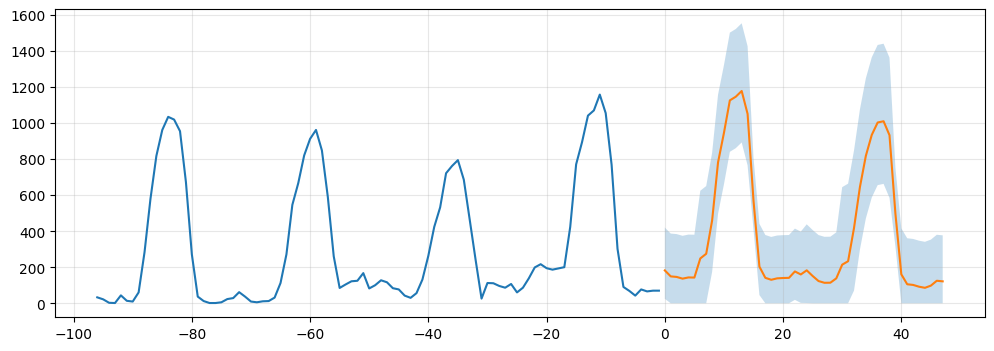

In [ ]:
NIGHT_SCALE, WIDEN = 0.8, 1.4        # <- WIDEN за коміркою 10 (+0.1 запас на помилку прогнозу погоди)
i0 = n - 1
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(i0, wx_f, fut)
ms_f = fit2(np.ones(len(O_all), bool), n)
dl = wx_f[:, WI["daylight"]]
p_f = pred2(ms_f, X_f) * lv_f * np.where(dl == 0, NIGHT_SCALE, 1.0)

q_all = calib(make_df(P["final"]))
lo_r = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f
hi_r = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f
sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"), "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_r * WIDEN, 0, None),
                    "upper_95": p_f + hi_r * WIDEN})
sub.to_csv("MAZKO_lgbm2_weight_decay_project.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(range(-96, 0), yarr[-96:]); plt.plot(range(48), sub.forecast)
plt.fill_between(range(48), sub.lower_95, sub.upper_95, alpha=.25); plt.show()

### experiment мультиплікативний інтервал

In [ ]:
def calib2(df, eps):
    r2 = (df.y - df.p) / (df.p + eps * df.lv)
    return {g: (r2[m.index].quantile(0.025), r2[m.index].quantile(0.975))
            for g, m in df.groupby(["k", "dl"])}

def eval_fold2(Pn, test_b, wide, eps, train_blocks=None):
    df = make_df(Pn)
    tr = df[df.b != test_b] if train_blocks is None else df[df.b.isin(train_blocks)]
    q = calib2(tr, eps); te = df[df.b == test_b]
    sc = te.p + eps * te.lv
    lo = np.array([q[(a, b)][0] for a, b in zip(te.k, te.dl)]) * sc
    hi = np.array([q[(a, b)][1] for a, b in zip(te.k, te.dl)]) * sc
    pred = te.p.to_numpy()
    lo = np.clip(pred + lo * wide, 0, None); hi = pred + hi * wide
    return score(te.y, pred, lo, hi)

R4 = []
for eps in [0.05, 0.15, 0.3]:
    for wd in [1.0, 1.2, 1.4, 1.6]:
        for tb in [1, 2]:
            R4.append(dict(eps=eps, widen=wd, test_block=tb, **eval_fold2(P["final"], tb, wd, eps)))
t4 = pd.DataFrame(R4)
print(t4.groupby(["eps", "widen"])[["Winkler", "coverage"]].mean().round(3))
print(t4[t4.test_block == 2].set_index(["eps", "widen"])[["Winkler", "coverage"]].round(3))

             Winkler  coverage
eps  widen                    
0.05 1.0    1623.184     0.902
     1.2    1642.484     0.950
     1.4    1725.275     0.965
     1.6    1836.946     0.975
0.15 1.0    1640.122     0.893
     1.2    1614.435     0.938
     1.4    1666.270     0.959
     1.6    1759.825     0.972
0.30 1.0    1658.122     0.888
     1.2    1603.406     0.930
     1.4    1630.160     0.955
     1.6    1703.167     0.969
             Winkler  coverage
eps  widen                    
0.05 1.0    1765.667     0.831
     1.2    1555.556     0.905
     1.4    1465.449     0.930
     1.6    1432.906     0.950
0.15 1.0    1889.839     0.812
     1.2    1612.656     0.882
     1.4    1470.031     0.919
     1.6    1413.966     0.943
0.30 1.0    1990.269     0.796
     1.2    1665.044     0.864
     1.4    1484.096     0.910
     1.6    1397.794     0.938


### experiment шум у погоді при навчанні

In [ ]:
rng = np.random.default_rng(0)
WCOLS = list(range(4, 11))               # погода у X2_all
sd = np.array([0.25, 1.0, 0.7, 1.5, 4.0, 0.0, 0.003])   # cloud, temp, wind, pressure, humidity, daylight, density
def noisy(X, scale_by_day=(1.0, 1.6)):
    Xn = X.copy()
    mult = np.where(Xn[:, 2] == 0, scale_by_day[0], scale_by_day[1])[:, None]
    Xn[:, WCOLS] += rng.normal(size=(len(Xn), 7)) * sd * mult
    Xn[:, 4] = np.clip(Xn[:, 4], 0, 1)   # cloud_cover
    return Xn

X2_orig = X2_all.copy()
X2_all = np.vstack([X2_orig, noisy(X2_orig)])       # подвоєна вибірка: чисті + зашумлені
Y_all_o, L_all_o, O_all_o = Y_all, L_all, O_all
Y_all, L_all, O_all = np.tile(Y_all_o, 2), np.tile(L_all_o, 2), np.tile(O_all_o, 2)

P["lgbm2_noise"] = {}
for bl in blocks:
    ms = fit2(O_all < bl[0] - 48, bl[0])
    te = np.isin(O_all, bl) & (np.arange(len(O_all)) < len(O_all_o))   # тест лише на чистих рядках
    for o in bl:
        t_ = (O_all == o) & (np.arange(len(O_all)) < len(O_all_o))
        P["lgbm2_noise"][int(o)] = pred2(ms, X2_all[t_]) * L_all[t_]

Pn2 = with_night_scale(P["lgbm2_noise"], 0.8)
print(pd.DataFrame([report(P["final"], "final (без шуму)"), report(Pn2, "з шумом у погоді")]).round(1).to_string())

# повернути як було
X2_all, Y_all, L_all, O_all = X2_orig, Y_all_o, L_all_o, O_all_o

              model  RMSE90  RMSE_d2  MAPE90  MAPE_d2  Winkler_b3  cov_b3
0  final (без шуму)   235.2    251.6    97.5    116.3      1558.8     0.9
1  з шумом у погоді   235.9    252.5    95.9    113.2      1544.4     0.9


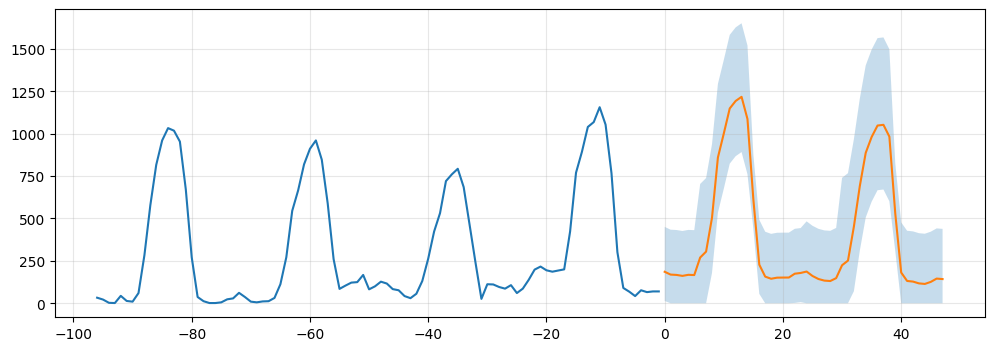

       forecast  lower_95  upper_95
count      48.0      48.0      48.0
mean      409.2     187.1     762.5
std       374.5     297.5     451.8
min       114.1       0.0     409.5
25%       150.3       0.0     429.3
50%       180.1       0.0     453.8
75%       630.7     341.7    1027.8
max      1217.5     891.8    1651.3


In [ ]:
NIGHT_SCALE, WIDEN = 0.8, 1.6

# калібрування на залишках моделі з шумом
P["final_noise"] = with_night_scale(P["lgbm2_noise"], NIGHT_SCALE)
q_all = calib(make_df(P["final_noise"]))

# перенавчання на всій історії: чисті + зашумлені рядки
rng = np.random.default_rng(1)
X2_orig, Y_o, L_o, O_o = X2_all.copy(), Y_all, L_all, O_all
X2_all = np.vstack([X2_orig, noisy(X2_orig)])
Y_all, L_all, O_all = np.tile(Y_o, 2), np.tile(L_o, 2), np.tile(O_o, 2)
ms_f = fit2(np.ones(len(O_all), bool), n)
X2_all, Y_all, L_all, O_all = X2_orig, Y_o, L_o, O_o      # повернути

i0 = n - 1
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(i0, wx_f, fut)
dl = wx_f[:, WI["daylight"]]
p_f = pred2(ms_f, X_f) * lv_f * np.where(dl == 0, NIGHT_SCALE, 1.0)

lo_r = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f
hi_r = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f
sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"), "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_r * WIDEN, 0, None),
                    "upper_95": p_f + hi_r * WIDEN})
sub.to_csv("MAZKO_final_lgbm2_noise_project.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(range(-96, 0), yarr[-96:]); plt.plot(range(48), sub.forecast)
plt.fill_between(range(48), sub.lower_95, sub.upper_95, alpha=.25); plt.show()
print(sub.describe().round(1))

### regression

In [ ]:
def fitq(mask, ref, alpha, half_life=180):
    w = L_all[mask] * 0.5 ** ((ref - O_all[mask]) / (24 * half_life))
    return lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=400,
                             learning_rate=0.03, num_leaves=15, min_child_samples=50,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=0, verbose=-1).fit(X2_all[mask], Y_all[mask], sample_weight=w)

QL, QH = {}, {}
for bl in blocks:
    mask = O_all < bl[0] - 48
    mlo, mhi = fitq(mask, bl[0], 0.025), fitq(mask, bl[0], 0.975)
    for o in bl:
        te = O_all == o
        QL[int(o)] = np.clip(mlo.predict(X2_all[te]), 0, None) * L_all[te]
        QH[int(o)] = np.clip(mhi.predict(X2_all[te]), 0, None) * L_all[te]
    print("block done")

def eval_q(Pn, wide, tb):
    df = make_df(Pn); te = df[df.b == tb]
    os_ = [o for o, b in zip(O90, B90) if b == tb]
    ql = np.concatenate([QL[o] for o in os_]); qh = np.concatenate([QH[o] for o in os_])
    p = te.p.to_numpy()
    lo = np.clip(p - (p - np.minimum(ql, p)) * wide, 0, None)
    hi = p + (np.maximum(qh, p) - p) * wide
    return score(te.y, p, lo, hi)

R5 = []
for wd in [1.0, 1.15, 1.3, 1.5]:
    for tb in [0, 1, 2]:
        R5.append(dict(method="quantile", widen=wd, block=tb, **eval_q(P["final_noise"], wd, tb)))
for tb in [0, 1, 2]:
    R5.append(dict(method="additive", widen=1.6, block=tb, **eval_fold(P["final_noise"], tb, 1.6)))
t5 = pd.DataFrame(R5)
print(t5[["method", "widen", "block", "Winkler", "coverage"]].round(3).to_string())
print(t5.groupby(["method", "widen"])[["Winkler", "coverage"]].mean().round(3))

In [ ]:
def fitq(mask, ref, alpha, half_life=180):
    w = 0.5 ** ((ref - O_all[mask]) / (24 * half_life))      # без L_all
    return lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=400,
                             learning_rate=0.03, num_leaves=15, min_child_samples=50,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=0, verbose=-1).fit(X2_all[mask], Y_all[mask], sample_weight=w)

QL, QH = {}, {}
for bl in blocks:
    mask = O_all < bl[0] - 48
    mlo, mhi = fitq(mask, bl[0], 0.025), fitq(mask, bl[0], 0.975)
    for o in bl:
        te = O_all == o
        QL[int(o)] = np.clip(mlo.predict(X2_all[te]), 0, None) * L_all[te]
        QH[int(o)] = np.clip(mhi.predict(X2_all[te]), 0, None) * L_all[te]

print("max верхньої межі:", max(v.max() for v in QH.values()).round(0))   # має бути ~ тисячі, не 1e10+

R5 = []
for wd in [1.0, 1.15, 1.3, 1.5]:
    for tb in [0, 1, 2]:
        R5.append(dict(method="quantile", widen=wd, block=tb, **eval_q(P["final_noise"], wd, tb)))
for tb in [0, 1, 2]:
    R5.append(dict(method="additive", widen=1.6, block=tb, **eval_fold(P["final_noise"], tb, 1.6)))
t5 = pd.DataFrame(R5)
print(t5.groupby(["method", "widen"])[["Winkler", "coverage"]].mean().round(3))
print(t5[t5.block == 2][["method", "widen", "Winkler", "coverage"]].round(3))

In [ ]:
summary = pd.concat([pd.DataFrame(R).assign(src="ablation"),
                     pd.DataFrame(R2).assign(src="night_scale")], ignore_index=True)
summary

## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

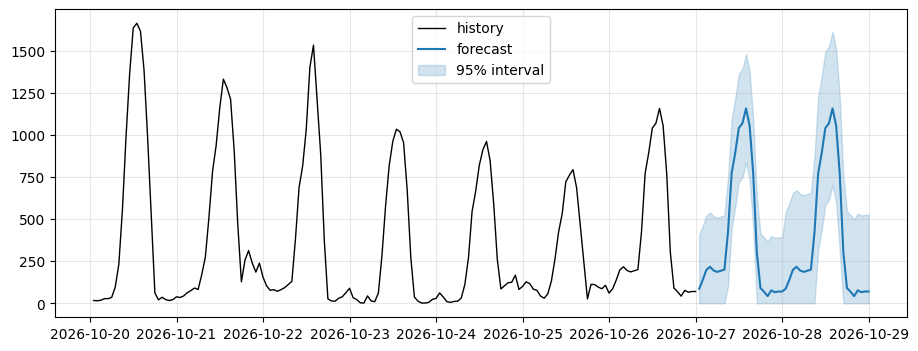

In [ ]:
# #forecast, lower_95, upper_95 = snaive(y)     # <-- replace with your model's forecast and 95% interval

# fig, ax = plt.subplots()
# ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
# ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
# ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
# ax.legend()
# plt.show()

In [ ]:
# def check_submission(sub: pd.DataFrame) -> None:
#     assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
#     assert len(sub) == H, f"need {H} rows, got {len(sub)}"
#     assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
#     assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
#     assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
#     assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
#         "the forecast must lie inside its interval"
#     print("format OK")


# submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
#                            "lower_95": lower_95, "upper_95": upper_95})
# check_submission(submission)

# FILE = f"MAZKO_final_lgbm2_noise_project.csv"
# submission.to_csv(FILE, index=False)
# print("saved", FILE)

# try:
#     from google.colab import files
#     files.download(FILE)
# except ImportError:
#     pass

format OK
saved MAZKO_final_lgbm2_noise_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.

In [ ]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")
submission=pd.read_csv(f"MAZKO_final_lgbm2_noise_project.csv")
check_submission(submission)

format OK
